In [1]:
import json
import operator
import re
from pathlib import Path
from typing import TypedDict, Annotated
from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

llm      = ChatOllama(model="llama3.2:latest", temperature=0)
DATA_DIR = Path("./data")
MAX_RETRY = 3

print(f"✅ Setup")

✅ Setup


In [2]:
# Schema di stato condiviso tra tutti i nodi
class StatoRichiesta(TypedDict, total=False):
    # Input
    richiesta:              str     # messaggio originale del cliente
    customer_id:            str     # ID del cliente
    claim_id:               str     # ID della pratica
    policy_id:              str     # ID dell'assicurazione del cliente
    loss_type:              str     # tipo di pratica dichiarata dall'utente (incidente, furto, allagamento)
    estimated_damage:       float   # valore stimato dell'indennizzo
    documents:              list    # lista dei documenti inviati dal cliente (come stringhe)

    # Risultati intermedi
    customer_name:          str     # prende il nome del cliente (probabilmente inutile, poi vediamo)
    risk_tier:              str     # possibile approfondimento futuro (sale con il numeri di incidenti)
    # policy_id:              str     # prende l'assicurazione effettiva (bisogna verificare che sia effettivamente posseduta dal cliente)
    product:                str     # prodotto assicurato (casa / macchina)
    coverage:               str     # da cosa ti copre l'assicurazione (bisogna verificare anche questo)
    deductible:             float   # franchigia (parte che il cliente deve pagare comunque)
    max_claim:              float   # tetto massimo coperto (probabilmente oltre questa soglia il perito non può agisce)
    active:                 bool    # flag che indica se l'assicurazione è attivo o meno (fondamentale)

    # Approfondimento di loss_type
    # loss_type:              str     # tipo di pratica
    required_documents:     list    # lista dei documenti richiesti dall'assicurazione (come stringhe)
    automatic_review_max:   float   # soglia massima per indennizzo automatico

    policy_customer_id:     str     # proprietario reale della polizza (deve coincidere con customer_id)
    documenti_mancanti:     list    # documenti richiesti non ancora inviati
    indennizzo:             float   # importo liquidato (danno - franchigia), 0 se rifiutato

    # INFO DI SISTEMA
    esito:                  str    # APPROVATO | ESCALATION | RIFIUTATO | AMBIGUO | ERRORE | TROPPI_TENTATIVI | FUORI_SCOPO | OK (valore intermedio usato dai router)
    motivazione:            str    # motivazione dell'esito
    risposta_finale:        str    # risposta finale data dall'agente
    retry_count:            int    # quanti cicli di chiarimento
    # chiarimento:            str    # risposta del cliente in caso di ambiguità
    errori:                 list   # lista degli errori riscontrati (non so se tenerla)

print("Campi dello stato:", list(StatoRichiesta.__annotations__.keys()))

Campi dello stato: ['richiesta', 'customer_id', 'claim_id', 'policy_id', 'loss_type', 'estimated_damage', 'documents', 'customer_name', 'risk_tier', 'product', 'coverage', 'deductible', 'max_claim', 'active', 'required_documents', 'automatic_review_max', 'policy_customer_id', 'documenti_mancanti', 'indennizzo', 'esito', 'motivazione', 'risposta_finale', 'retry_count', 'errori']


In [3]:
class Agent:
    """Agente ReAct"""

    def __init__(self, model, tools, system="", stop_dopo_tool=False):
        self.system = system

        class AgentState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]

        graph = StateGraph(AgentState)
        graph.add_node("llm",    self.call_llm)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        # stop_dopo_tool=True: dopo aver eseguito i tool l'agente si ferma (niente secondo giro
        # col LLM). Con un modello piccolo evita loop di tool call e risparmia una chiamata.
        graph.add_edge("action", END if stop_dopo_tool else "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()

        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state):
        """Controlla se il LLM ha richiesto almeno un tool call."""
        return len(state["messages"][-1].tool_calls) > 0

    def call_llm(self, state):
        """Nodo llm: invoca il modello con i messaggi correnti."""
        messages = state["messages"]
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {"messages": [message]}

    def take_action(self, state):
        """Nodo action: esegue i tool richiesti e raccoglie i risultati."""
        tool_calls = state["messages"][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"    🔧 {t['name']}({t['args']})")
            if t["name"] not in self.tools:
                result = f"Tool '{t['name']}' non esiste. Disponibili: {list(self.tools.keys())}"
            else:
                result = self.tools[t["name"]].invoke(t["args"])
            results.append(ToolMessage(
                tool_call_id=t["id"], name=t["name"], content=str(result)
            ))
        return {"messages": results}

    def run(self, prompt: str) -> list:
        """Esegue l'agente e ritorna TUTTI i messaggi (serve per leggere i risultati dei tool)."""
        return self.graph.invoke({"messages": [HumanMessage(content=prompt)]})["messages"]

    def ask(self, prompt: str) -> str:
        """Interfaccia comoda: manda un prompt, ritorna il testo finale dell'agente."""
        return self.run(prompt)[-1].content

print("✅ Classe Agent definita")

✅ Classe Agent definita


## Dati, logica deterministica e tool
Le funzioni pure (`cerca_pratica`, `confronta`) sono la *verità* su dati e regole; i tool le espongono agli agenti.

In [4]:
def _carica(nome):
    return json.loads((DATA_DIR / nome).read_text(encoding="utf-8"))

CLAIMS       = {c["claim_id"]:    c for c in _carica("claims.json")}
CUSTOMERS    = {c["customer_id"]: c for c in _carica("customers.json")}
POLICIES     = {p["policy_id"]:   p for p in _carica("policies.json")}
REQUIREMENTS = {r["loss_type"]:   r for r in _carica("requirements.json")}

CLAIM_RE    = re.compile(r"\bCL\d+\b", re.I)
CUSTOMER_RE = re.compile(r"\bAS\d+\b", re.I)

def _trova(regex, testo):
    m = regex.search(testo or "")
    return m.group().upper() if m else None

def _eur(x):
    return f"{x:.2f}".replace(".", ",") + " €"

# ── Logica deterministica ────────────────────────────────────────────────
def cerca_pratica(claim_id, customer_id):
    """Lookup nei JSON: pratica + polizza + cliente + requisiti. Ritorna un dict piatto
    con le stesse chiavi dello stato, oppure {'errore': ...}."""
    base = {"claim_id": claim_id, "customer_id": customer_id}
    claim = CLAIMS.get(claim_id)
    if not claim:
        return {**base, "errore": f"Pratica {claim_id} non trovata"}
    polizza = POLICIES.get(claim["policy_id"])
    if not polizza:
        return {**base, "errore": f"Polizza {claim['policy_id']} non trovata"}
    req = REQUIREMENTS.get(claim["loss_type"])
    if not req:
        return {**base, "errore": f"Tipo di sinistro '{claim['loss_type']}' non gestito"}
    cliente = CUSTOMERS.get(customer_id, {})
    return {
        **base,
        "policy_id":            polizza["policy_id"],
        "policy_customer_id":   polizza["customer_id"],
        "loss_type":            claim["loss_type"],
        "estimated_damage":     float(claim["estimated_damage"]),
        "documents":            list(claim["documents"]),
        "customer_name":        cliente.get("name", ""),
        "risk_tier":            cliente.get("risk_tier", ""),
        "product":              polizza["product"],
        "coverage":             polizza["coverage"],
        "deductible":           float(polizza["deductible"]),
        "max_claim":            float(polizza["max_claim"]),
        "active":               bool(polizza["active"]),
        "required_documents":   list(req["required_documents"]),
        "automatic_review_max": float(req["automatic_review_max"]),
    }

def confronta(richiesti, inviati):
    inviati_norm = {d.strip().lower() for d in inviati}
    mancanti = [d for d in richiesti if d.strip().lower() not in inviati_norm]
    return {"mancanti": mancanti, "completo": not mancanti}

# ── Tool (uno per agente) ────────────────────────────────────────────────
@tool
def classifica_richiesta(categoria: str, motivo: str) -> str:
    """Registra la classificazione della richiesta del cliente.
    categoria: 'SINISTRO' se il cliente vuole aprire o gestire una pratica di sinistro
    assicurativo (incidente, furto, danni d'acqua...), 'ALTRO' per qualsiasi altra richiesta.
    motivo: breve spiegazione della scelta."""
    categoria = categoria.strip().upper()
    if categoria not in {"SINISTRO", "ALTRO"}:
        return json.dumps({"errore": "categoria non valida, usa SINISTRO oppure ALTRO"})
    return json.dumps({"categoria": categoria, "motivo": motivo}, ensure_ascii=False)

@tool
def recupera_pratica(claim_id: str, customer_id: str) -> str:
    """Recupera pratica, polizza, cliente e requisiti documentali.
    claim_id: ID della pratica, formato CLxxx (es. CL001).
    customer_id: ID del cliente, formato ASxxx (es. AS001)."""
    return json.dumps(cerca_pratica(claim_id.strip().upper(), customer_id.strip().upper()),
                      ensure_ascii=False)

@tool
def confronta_documenti(richiesti: list[str], inviati: list[str]) -> str:
    """Confronta i documenti richiesti con quelli inviati e ritorna quelli mancanti.
    richiesti: lista dei documenti richiesti dalla polizza.
    inviati: lista dei documenti inviati dal cliente."""
    return json.dumps(confronta(richiesti, inviati), ensure_ascii=False)

@tool
def invia_risposta(testo: str) -> str:
    """Invia al cliente il messaggio finale sull'esito della pratica.
    testo: il messaggio completo, in italiano."""
    return json.dumps({"inviata": True})

print("✅ Dati caricati:", len(CLAIMS), "pratiche,", len(POLICIES), "polizze,", len(CUSTOMERS), "clienti")

✅ Dati caricati: 4 pratiche, 3 polizze, 3 clienti


## I 4 agenti
Ognuno è un `Agent` ReAct con il suo tool. `stop_dopo_tool=True`: l'agente chiama il tool e si ferma.

In [5]:
agente_orchestratore = Agent(llm, [classifica_richiesta], stop_dopo_tool=True, system=(
    "Sei l'orchestratore di un sistema di gestione sinistri assicurativi. "
    "Leggi la richiesta del cliente e chiama SEMPRE lo strumento classifica_richiesta: "
    "categoria='SINISTRO' se il cliente vuole aprire o gestire una pratica di sinistro, "
    "altrimenti categoria='ALTRO'."))

agente_estrazione = Agent(llm, [recupera_pratica], stop_dopo_tool=True, system=(
    "Sei l'agente di estrazione dati. Dalla richiesta del cliente individua l'ID pratica "
    "(formato CLxxx) e l'ID cliente (formato ASxxx) e chiama SEMPRE lo strumento "
    "recupera_pratica con questi due valori, copiati esattamente dal testo."))

agente_documenti = Agent(llm, [confronta_documenti], stop_dopo_tool=True, system=(
    "Sei l'agente di verifica documentale. Chiama SEMPRE lo strumento confronta_documenti "
    "passando le due liste esattamente come ti vengono fornite."))

agente_esito = Agent(llm, [invia_risposta], stop_dopo_tool=True, system=(
    "Sei l'agente che comunica al cliente l'esito della sua pratica assicurativa. "
    "Scrivi un messaggio in italiano, cortese e chiaro (massimo 5 frasi), basato SOLO sui dati "
    "forniti: non inventare importi, motivi o scadenze. Poi chiama lo strumento invia_risposta "
    "passando il messaggio nel parametro testo."))

# ── Helper per leggere cosa hanno fatto gli agenti ──────────────────────────
def _chiama_agente(agente, prompt):
    try:
        return agente.run(prompt)
    except Exception as e:                      # Ollama spento, loop di tool, ecc.
        print(f"    ⚠️  agente non disponibile ({type(e).__name__}): uso il fallback in codice")
        return []

def _risultato_tool(messaggi, nome):
    """JSON prodotto dall'ultimo ToolMessage del tool `nome` (None se assente/illeggibile)."""
    for m in reversed(messaggi):
        if isinstance(m, ToolMessage) and m.name == nome:
            try:
                return json.loads(m.content)
            except json.JSONDecodeError:
                return None
    return None

def _args_tool(messaggi, nome):
    """Argomenti dell'ultima tool call a `nome` fatta dal LLM (None se assente)."""
    for m in reversed(messaggi):
        if isinstance(m, AIMessage):
            for tc in m.tool_calls:
                if tc["name"] == nome:
                    return tc["args"]
    return None

print("✅ 4 agenti creati")

✅ 4 agenti creati


## Nodi e router
Agenti: `orchestratore`, `estrapola_dati`, `analizza_documenti`, `formula_esito`. Il resto è codice deterministico; `chiedi_chiarimenti` e `chiama_perito` usano `interrupt()`.

In [6]:
# ═════════════ AGENTE 1 — orchestratore ═════════════
def orchestratore(state):
    richiesta = state["richiesta"]
    msgs = _chiama_agente(agente_orchestratore, f"Richiesta del cliente:\n{richiesta}")
    ris = _risultato_tool(msgs, "classifica_richiesta")
    if not ris or "categoria" not in ris:      # fallback: il LLM non ha usato il tool
        print("    ↩️  classificazione mancante: uso il fallback in codice")
        categoria = "SINISTRO" if _trova(CLAIM_RE, richiesta) else "ALTRO"
    else:
        categoria = ris["categoria"]

    if categoria != "SINISTRO":
        return {"esito": "FUORI_SCOPO",
                "motivazione": "La richiesta non riguarda una pratica di sinistro."}
    # Una pratica va identificata: servono ID pratica e ID cliente (verifica di proprietà)
    if not _trova(CLAIM_RE, richiesta) or not _trova(CUSTOMER_RE, richiesta):
        return {"esito": "FUORI_SCOPO",
                "motivazione": "Mancano i riferimenti: servono l'ID pratica (es. CL001) "
                               "e l'ID cliente (es. AS001)."}
    return {"esito": "OK"}

def router_orchestratore(state):
    return state["esito"]                      # OK | FUORI_SCOPO


# ═════════════ AGENTE 2 — estrazione dati ═════════════
def estrapola_dati(state):
    richiesta = state["richiesta"]
    claim_atteso, cliente_atteso = _trova(CLAIM_RE, richiesta), _trova(CUSTOMER_RE, richiesta)
    msgs = _chiama_agente(agente_estrazione, f"Richiesta del cliente:\n{richiesta}")
    dati = _risultato_tool(msgs, "recupera_pratica")
    # Guardrail: gli ID usati dall'agente devono coincidere con quelli presenti nel testo
    if (not dati or dati.get("claim_id") != claim_atteso
            or dati.get("customer_id") != cliente_atteso):
        print("    ↩️  estrazione mancante o incoerente: uso il fallback in codice")
        dati = cerca_pratica(claim_atteso, cliente_atteso)
    if "errore" in dati:
        return {"claim_id": dati["claim_id"], "customer_id": dati["customer_id"],
                "errori": [dati["errore"]]}
    return dati                                # chiavi = campi dello stato


# ═════════════ verifica_polizza (codice) ═════════════
def verifica_polizza(state):
    if state.get("errori"):
        motivo = "; ".join(state["errori"])
    elif state["customer_id"] != state["policy_customer_id"]:
        motivo = f"La pratica {state['claim_id']} non appartiene al cliente {state['customer_id']}."
    elif not state["active"]:
        motivo = f"La polizza {state['policy_id']} non è attiva."
    elif state["coverage"] != state["loss_type"]:
        motivo = (f"La polizza {state['policy_id']} copre '{state['coverage']}', "
                  f"non '{state['loss_type']}'.")
    else:
        return {"esito": "OK"}
    return {"esito": "RIFIUTATO", "motivazione": motivo}

def router_verifica_polizza(state):
    return state["esito"]                      # OK | RIFIUTATO


# ═════════════ AGENTE 3 — verifica documenti ═════════════
def analizza_documenti(state):
    richiesti, inviati = state["required_documents"], state["documents"]
    prompt = (f"Documenti richiesti: {json.dumps(richiesti)}\n"
              f"Documenti inviati: {json.dumps(inviati)}")
    msgs = _chiama_agente(agente_documenti, prompt)
    ris_agente = _risultato_tool(msgs, "confronta_documenti")
    verita = confronta(richiesti, inviati)
    # Guardrail: il confronto in codice è l'unica fonte di verità
    if not ris_agente or set(ris_agente.get("mancanti", [])) != set(verita["mancanti"]):
        print("    ↩️  risultato dell'agente mancante o diverso dal calcolo: uso il codice")
    mancanti = verita["mancanti"]

    if not mancanti:
        return {"esito": "OK", "documenti_mancanti": []}
    retry = state.get("retry_count", 0)
    if retry >= MAX_RETRY:
        return {"esito": "TROPPI_TENTATIVI", "documenti_mancanti": mancanti,
                "motivazione": f"Documenti ancora mancanti dopo {MAX_RETRY} richieste: "
                               f"{', '.join(mancanti)}."}
    # il contatore si incrementa qui (non in chiedi_chiarimenti, che viene rieseguito dopo l'interrupt)
    return {"esito": "AMBIGUO", "documenti_mancanti": mancanti, "retry_count": retry + 1}

def router_analizza_documenti(state):
    return state["esito"]                      # OK | AMBIGUO | TROPPI_TENTATIVI


# ═════════════ chiedi_chiarimenti (interrupt) ═════════════
def chiedi_chiarimenti(state):
    risposta = interrupt({
        "tipo": "chiarimenti",
        "pratica": state["claim_id"],
        "documenti_mancanti": state["documenti_mancanti"],
        "tentativo": state["retry_count"],
    })
    nuovi = risposta if isinstance(risposta, list) else [risposta]
    attuali = list(state["documents"])
    return {"documents": attuali + [d for d in nuovi if d and d not in attuali]}


# ═════════════ verifica_budget (codice) ═════════════
def verifica_budget(state):
    danno, franchigia = state["estimated_damage"], state["deductible"]
    tetto, soglia = state["max_claim"], state["automatic_review_max"]
    if danno <= franchigia:
        return {"esito": "RIFIUTATO",
                "motivazione": f"Il danno stimato ({_eur(danno)}) non supera la franchigia "
                               f"({_eur(franchigia)}): nessun indennizzo dovuto."}
    if danno > tetto:
        return {"esito": "RIFIUTATO",
                "motivazione": f"Il danno stimato ({_eur(danno)}) supera il massimale "
                               f"della polizza ({_eur(tetto)})."}
    if danno <= soglia:
        return {"esito": "APPROVATO",
                "motivazione": f"Danno stimato ({_eur(danno)}) entro la soglia di "
                               f"approvazione automatica ({_eur(soglia)})."}
    return {"esito": "ESCALATION",
            "motivazione": f"Danno stimato ({_eur(danno)}) oltre la soglia automatica "
                           f"({_eur(soglia)}): necessaria la perizia."}

def router_verifica_budget(state):
    return state["esito"]                      # APPROVATO | ESCALATION | RIFIUTATO


# ═════════════ chiama_perito (interrupt) ═════════════
def chiama_perito(state):
    decisione = interrupt({
        "tipo": "perito",
        "pratica": state["claim_id"],
        "danno_stimato": state["estimated_damage"],
        "soglia_automatica": state["automatic_review_max"],
        "massimale": state["max_claim"],
    })
    # decisione attesa: {"approvato": bool, "note": str}
    approvato = bool(decisione.get("approvato")) if isinstance(decisione, dict) else False
    note = decisione.get("note", "") if isinstance(decisione, dict) else ""
    if approvato:
        return {"esito": "APPROVATO", "motivazione": f"Approvata dal perito. {note}".strip()}
    return {"esito": "RIFIUTATO", "motivazione": f"Rifiutata dal perito. {note}".strip()}

def router_decisione_perito(state):
    return state["esito"]                      # APPROVATO | RIFIUTATO


# ═════════════ approva_claim / rifiuta_claim ═════════════
def approva_claim(state):
    return {"esito": "APPROVATO",
            "indennizzo": state["estimated_damage"] - state["deductible"]}

def rifiuta_claim(state):
    esito = "FUORI_SCOPO" if state.get("esito") == "FUORI_SCOPO" else "RIFIUTATO"
    return {"esito": esito, "indennizzo": 0.0,
            "motivazione": state.get("motivazione") or "Pratica rifiutata."}


# ═════════════ AGENTE 4 — esito finale ═════════════
def _risposta_standard(fatti):
    nome = fatti["cliente"] or "cliente"
    if fatti["esito"] == "APPROVATO":
        return (f"Gentile {nome}, la pratica {fatti['pratica']} è stata approvata. "
                f"Indennizzo: {fatti['indennizzo']}. {fatti['motivazione']}")
    if fatti["esito"] == "FUORI_SCOPO":
        return f"Gentile {nome}, non posso gestire questa richiesta. {fatti['motivazione']}"
    return (f"Gentile {nome}, la pratica {fatti['pratica']} è stata rifiutata. "
            f"Motivo: {fatti['motivazione']}")

def formula_esito(state):
    fatti = {
        "esito":        state["esito"],
        "motivazione":  state.get("motivazione", ""),
        "pratica":      state.get("claim_id", ""),
        "cliente":      state.get("customer_name", ""),
        "indennizzo":   _eur(state["indennizzo"]) if state["esito"] == "APPROVATO" else None,
    }
    prompt = ("Dati della pratica:\n" + json.dumps(fatti, ensure_ascii=False, indent=2)
              + "\nScrivi il messaggio per il cliente e invialo.")
    msgs = _chiama_agente(agente_esito, prompt)

    args = _args_tool(msgs, "invia_risposta")
    testo = (args or {}).get("testo", "") if args else ""
    if not testo and msgs and isinstance(msgs[-1], AIMessage):
        testo = msgs[-1].content or ""
    if len(testo.strip()) < 20:
        print("    ↩️  messaggio dell'agente assente: uso il testo standard")
        testo = _risposta_standard(fatti)
    # Guardrail sui numeri: il messaggio non deve contenere cifre che non sono nei dati
    # (importi, date, giorni inventati) e, se approvato, deve riportare l'indennizzo corretto
    numeri = lambda s: set(re.findall(r"\d+", s))
    inventati = numeri(testo) - numeri(json.dumps(fatti, ensure_ascii=False))
    manca_importo = state["esito"] == "APPROVATO" and str(int(state["indennizzo"])) not in testo
    if inventati or manca_importo:
        print("    ↩️  il messaggio contiene numeri non verificati o manca l'importo: uso il testo standard")
        testo = _risposta_standard(fatti)
    return {"risposta_finale": testo}

print("✅ Nodi e router definiti")

✅ Nodi e router definiti


In [7]:
builder = StateGraph(StatoRichiesta)

# Aggiungi nodi
builder.add_node("orchestratore",       orchestratore)
builder.add_node("estrapola_dati",      estrapola_dati)
builder.add_node("verifica_polizza",    verifica_polizza)
builder.add_node("analizza_documenti",  analizza_documenti)
builder.add_node("verifica_budget",     verifica_budget)
builder.add_node("rifiuta_claim",       rifiuta_claim)
builder.add_node("approva_claim",       approva_claim)
builder.add_node("chiedi_chiarimenti",  chiedi_chiarimenti)
builder.add_node("chiama_perito",       chiama_perito)
builder.add_node("formula_esito",       formula_esito)

# Archi fissi
builder.add_edge(START,                 "orchestratore")
builder.add_edge("estrapola_dati",      "verifica_polizza")
builder.add_edge("chiedi_chiarimenti",  "analizza_documenti")
builder.add_edge("rifiuta_claim",       "formula_esito")
builder.add_edge("approva_claim",       "formula_esito")
builder.add_edge("formula_esito",       END)

# Archi condizionali

#Ciclo
builder.add_conditional_edges(
    "analizza_documenti",
    router_analizza_documenti,
    {
        "OK": "verifica_budget",                    # il claim è in regola
        "AMBIGUO": "chiedi_chiarimenti",            # il claim non ha tutti i requisiti
        "TROPPI_TENTATIVI": "rifiuta_claim"         # il claim non è ancora completo dopo MAX_RETRY tentativi
    }
)

# If
builder.add_conditional_edges(
    "orchestratore",
    router_orchestratore,
    {
        "OK": "estrapola_dati",                     # la polizza è valida
        "FUORI_SCOPO": "rifiuta_claim"              # la polizza non è valida
    }
)

# If
builder.add_conditional_edges(
    "verifica_polizza",
    router_verifica_polizza,
    {
        "OK": "analizza_documenti",                 # la polizza è valida
        "RIFIUTATO": "rifiuta_claim"                # la polizza non è valida
    }
)

# If
builder.add_conditional_edges(
    "verifica_budget",
    router_verifica_budget,
    {
        "APPROVATO": "approva_claim",               # il claim è entro il tetto massimo dell'approvazione automatica
        "ESCALATION": "chiama_perito",              # il claim è oltre il budget di approvazione automatica, ma sotto il tetto massimo
        "RIFIUTATO": "rifiuta_claim"                # il claim è fuori dal tetto massimo
    }
)

# If
builder.add_conditional_edges(
    "chiama_perito",
    router_decisione_perito,
    {
        "APPROVATO": "approva_claim",               # il perito ha approvato il claim
        "RIFIUTATO": "rifiuta_claim"                # il perito ha rifiutato il claim
    }
)

# Compila il grafo
graph = builder.compile(checkpointer=MemorySaver())
print("✅ Grafo compilato — nodi:", list(builder.nodes.keys()))

✅ Grafo compilato — nodi: ['orchestratore', 'estrapola_dati', 'verifica_polizza', 'analizza_documenti', 'verifica_budget', 'rifiuta_claim', 'approva_claim', 'chiedi_chiarimenti', 'chiama_perito', 'formula_esito']


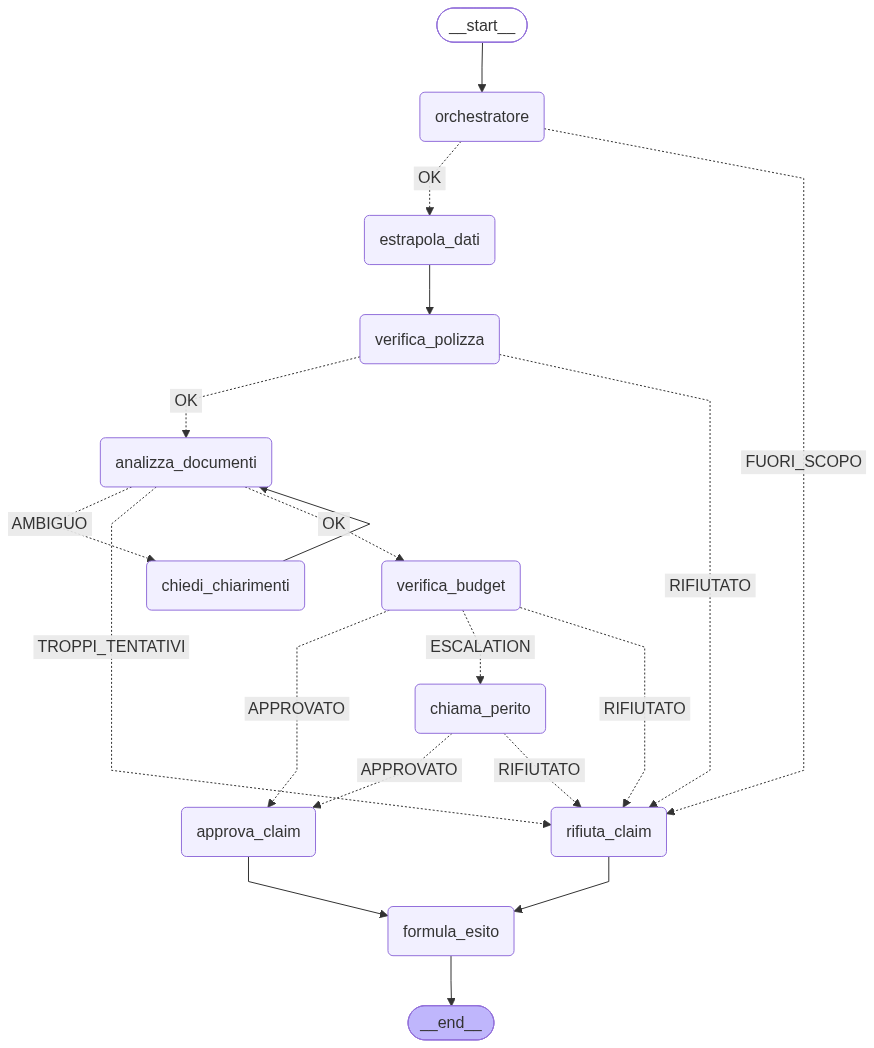

In [8]:
# Visualizza il grafo (richiede graphviz o pillow)
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_mermaid())

## Test
Il loop gestisce gli `interrupt()` simulando le risposte di cliente e perito.

In [9]:
from uuid import uuid4

def esegui(richiesta, risposte=()):
    """Esegue il grafo. `risposte` = risposte simulate agli interrupt, nell'ordine in cui arrivano."""
    risposte = list(risposte)
    config = {"configurable": {"thread_id": str(uuid4())}}   # un thread per esecuzione
    graph.invoke({"richiesta": richiesta, "retry_count": 0}, config)
    while graph.get_state(config).next:                      # grafo sospeso su un interrupt
        info = graph.get_state(config).tasks[0].interrupts[0].value
        risp = risposte.pop(0)
        print(f"    ⏸️  {info['tipo']} → risposta simulata: {risp}")
        graph.invoke(Command(resume=risp), config)
    return graph.get_state(config).values

PERITO_OK = {"approvato": True, "note": "Danni verificati."}

scenari = [
    ("CL001 — approvazione automatica",
     "Buongiorno, sono Pietro Sala (AS001) e vorrei aprire la pratica CL001 per il tamponamento.", []),
    ("CL002 — chiarimenti + perito",
     "Sono Chiara Riva, cliente AS002: allagamento in casa, pratica CL002.", [["repair_invoice"], PERITO_OK]),
    ("CL003 — polizza non attiva",
     "Sono Enrico Villa (AS003), pratica CL003 per il mio incidente.", []),
    ("CL004 — sinistro non coperto",
     "Cliente AS001, pratica CL004: mi hanno rubato l'auto.", []),
    ("CL001 con cliente sbagliato",
     "Sono AS002 e voglio gestire la pratica CL001.", []),
    ("CL002 — documenti mai inviati",
     "Cliente AS002, pratica CL002 per l'allagamento.", [[], [], []]),
    ("Richiesta fuori scopo",
     "Che tempo farà domani a Bari?", []),
    ("Richiesta incompleta",
     "Vorrei aprire una pratica per il mio incidente.", []),
]

for titolo, richiesta, risposte in scenari:
    print("\n" + "═" * 70 + f"\n{titolo}\n" + "═" * 70)
    s = esegui(richiesta, risposte)
    print(f"  ESITO: {s['esito']}  |  indennizzo: {s.get('indennizzo')}")
    print(f"  MOTIVO: {s.get('motivazione')}")
    print(f"  RISPOSTA AL CLIENTE:\n{s['risposta_finale']}")


══════════════════════════════════════════════════════════════════════
CL001 — approvazione automatica
══════════════════════════════════════════════════════════════════════
    ⚠️  agente non disponibile (ConnectError): uso il fallback in codice
    ↩️  classificazione mancante: uso il fallback in codice
    ⚠️  agente non disponibile (ConnectError): uso il fallback in codice
    ↩️  estrazione mancante o incoerente: uso il fallback in codice
    ⚠️  agente non disponibile (ConnectError): uso il fallback in codice
    ↩️  risultato dell'agente mancante o diverso dal calcolo: uso il codice
    ⚠️  agente non disponibile (ConnectError): uso il fallback in codice
    ↩️  messaggio dell'agente assente: uso il testo standard
  ESITO: APPROVATO  |  indennizzo: 950.0
  MOTIVO: Danno stimato (1200,00 €) entro la soglia di approvazione automatica (3000,00 €).
  RISPOSTA AL CLIENTE:
Gentile Pietro Sala, la pratica CL001 è stata approvata. Indennizzo: 950,00 €. Danno stimato (1200,00 €) entro l